# 01. Data Profiling – IEEE-CIS Fraud Detection

## Objectives

- Inspect dataset structure and data types.
- Analyze missing values and feature cardinality.
- Check duplicate transaction IDs.
- Validate binary fraud labels.
- Analyze class imbalance.
- Compare raw data with dataset provenance.
- Export data quality reports.

This notebook performs exploratory data profiling only.
No raw data is modified.

## 1. Import thư viện và khai báo cấu hình

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "configs" / "dataset.yaml").exists():
    raise RuntimeError("Cannot locate project root.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    load_config,
    load_manifest,
    load_ieee_transactions,
    load_ieee_identity,
)

from src.data_profiling import (
    dataset_overview,
    column_profile,
    missing_value_report,
    duplicate_report,
    target_distribution,
    target_validation,
    numerical_statistics,
    export_report,
)

pd.set_option("display.max_columns", 30)

sns.set_theme(style="whitegrid")

print("Project root:", PROJECT_ROOT)

Project root: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining


In [2]:
config = load_config()

ieee_config = config["datasets"]["ieee_cis"]

REPORT_DIR = PROJECT_ROOT / config["paths"]["profiling_dir"] / "ieee_cis"

FIGURE_DIR = PROJECT_ROOT / config["paths"]["figures_dir"] / "ieee_cis"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

ID_COLUMN = ieee_config["id_column"]
TARGET_COLUMN = ieee_config["target_column"]
TIME_COLUMN = ieee_config["time_column"]

print("Report directory:", REPORT_DIR)
print("Figure directory:", FIGURE_DIR)

Report directory: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis
Figure directory: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\figures\ieee_cis


## 2. Kiểm tra kích thước và đối chiếu Manifest

In [4]:
manifest = load_manifest()

display(manifest)

,dataset_name,dataset_role,source_url,version,license,download_date,file_name,file_size_mb,num_rows,num_columns,sha256,local_path,recorded_date,notes
0,IEEE-CIS Fraud Detection,Main,https://www.kaggle.com/competitions/ieee-fraud...,Unverified,Kaggle Competition Rules,2026-11-24,train_identity.csv,25.30,144233,41,b63c725d8377be90a995268d97f347c17d456b95db4580...,data/raw/ieee_cis/train_identity.csv,2026-11-24,NaN
1,IEEE-CIS Fraud Detection,Main,https://www.kaggle.com/competitions/ieee-fraud...,Unverified,Kaggle Competition Rules,2026-11-24,train_transaction.csv,651.69,590540,394,3a5c83ab6b3cc13dcabe5ffa9f522307fd5f7f7b6e6f6a...,data/raw/ieee_cis/train_transaction.csv,2026-11-24,NaN
2,Bank Account Fraud,Secondary,https://www.kaggle.com/datasets/sgpjesus/bank-...,Unverified,To be verified,2026-11-24,Base.csv,203.54,1000000,32,7bf10a37ce07e72e14c1b09e5efee3d27261baff4facc7...,data/raw/baf/Base.csv,2026-11-24,NaN
3,Bank Account Fraud,Secondary,https://www.kaggle.com/datasets/sgpjesus/bank-...,Unverified,To be verified,2026-11-24,Variant I.csv,203.51,1000000,32,48c637a255d1fa4515da4286ccb99251412a6d905937ec...,data/raw/baf/Variant I.csv,2026-11-24,NaN
4,Bank Account Fraud,Secondary,https://www.kaggle.com/datasets/sgpjesus/bank-...,Unverified,To be verified,2026-11-24,Variant II.csv,203.65,1000000,32,60bcd971cf28779abb183c3286990cff9a87275bd8b83d...,data/raw/baf/Variant II.csv,2026-11-24,NaN
5,Bank Account Fraud,Secondary,https://www.kaggle.com/datasets/sgpjesus/bank-...,Unverified,To be verified,2026-11-24,Variant III.csv,240.52,1000000,34,64693e549cff7ef802cf043fc7c937839e5929966e33a0...,data/raw/baf/Variant III.csv,2026-11-24,NaN
6,Bank Account Fraud,Secondary,https://www.kaggle.com/datasets/sgpjesus/bank-...,Unverified,To be verified,2026-11-24,Variant IV.csv,203.65,1000000,32,c6cddebbad34fa262a278deeb7985e7b669a64308d26e4...,data/raw/baf/Variant IV.csv,2026-11-24,NaN
7,Bank Account Fraud,Secondary,https://www.kaggle.com/datasets/sgpjesus/bank-...,Unverified,To be verified,2026-11-24,Variant V.csv,240.53,1000000,34,470899bbef97c32a100528d63e863e1b1036df9501df6e...,data/raw/baf/Variant V.csv,2026-11-24,NaN


In [5]:
df = load_ieee_transactions()

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (590540, 394)


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,...,V325,V326,V327,V328,V329,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
manifest_record = manifest.loc[manifest["file_name"] == "train_transaction.csv"]

if len(manifest_record) != 1:
    raise ValueError(
        "Expected exactly one manifest record " "for train_transaction.csv"
    )

record = manifest_record.iloc[0]

integrity_report = pd.DataFrame(
    [
        {
            "property": "num_rows",
            "expected": int(record["num_rows"]),
            "actual": df.shape[0],
        },
        {
            "property": "num_columns",
            "expected": int(record["num_columns"]),
            "actual": df.shape[1],
        },
    ]
)

integrity_report["is_match"] = (
    integrity_report["expected"] == integrity_report["actual"]
)

display(integrity_report)

export_report(integrity_report, REPORT_DIR / "transaction_integrity.csv")

assert integrity_report["is_match"].all(), "Dataset dimensions do not match manifest."

,property,expected,actual,is_match
0,num_rows,590540,590540,True
1,num_columns,394,394,True


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_integrity.csv


## 3. Dataset Overview

In [7]:
overview = dataset_overview(df, dataset_name="IEEE-CIS Transaction")

display(overview.T)

export_report(overview, REPORT_DIR / "transaction_overview.csv")

,0
dataset_name,IEEE-CIS Transaction
num_rows,590540
num_columns,394
numeric_columns,380
non_numeric_columns,14
total_missing_values,95566686
missing_rate_pct,41.073431
memory_usage_mb,1791.667439


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_overview.csv


## 4. Column Profiling

In [8]:
profile = column_profile(df)

display(profile.head(20))

export_report(profile, REPORT_DIR / "transaction_column_profile.csv")

,column_name,dtype,non_null_count,missing_count,missing_rate_pct,unique_count,unique_rate_pct,is_constant,is_all_missing
0,TransactionID,int64,590540,0,0.000000,590540,100.000000,False,False
1,isFraud,int64,590540,0,0.000000,2,0.000339,False,False
2,TransactionDT,int64,590540,0,0.000000,573349,97.088936,False,False
3,TransactionAmt,float64,590540,0,0.000000,20902,3.539472,False,False
4,ProductCD,str,590540,0,0.000000,5,0.000847,False,False
5,card1,int64,590540,0,0.000000,13553,2.295018,False,False
6,card2,float64,581607,8933,1.512683,500,0.084668,False,False
7,card3,float64,588975,1565,0.265012,114,0.019304,False,False
8,card4,str,588963,1577,0.267044,4,0.000677,False,False
9,card5,float64,586281,4259,0.721204,119,0.020151,False,False


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_column_profile.csv


## 5. Phân tích kiểu dữ liệu

In [9]:
dtype_distribution = (
    df.dtypes.astype(str)
    .value_counts()
    .rename_axis("dtype")
    .reset_index(name="column_count")
)

display(dtype_distribution)

export_report(dtype_distribution, REPORT_DIR / "transaction_dtype_distribution.csv")

,dtype,column_count
0,float64,376
1,str,14
2,int64,4


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_dtype_distribution.csv


## 6. Missing Value Analysis

In [11]:
missing_report = missing_value_report(df)

display(missing_report.head(30))

export_report(missing_report, REPORT_DIR / "transaction_missing_values.csv")

KeyboardInterrupt: 

## 7. Thống kê mức độ thiếu dữ liệu

In [12]:
thresholds = config["profiling"]["missing_rate_thresholds"]

missing_summary = []

for threshold in thresholds:

    count = (profile["missing_rate_pct"] >= threshold * 100).sum()

    missing_summary.append(
        {"missing_threshold_pct": threshold * 100, "num_columns": int(count)}
    )

missing_summary = pd.DataFrame(missing_summary)

display(missing_summary)

export_report(missing_summary, REPORT_DIR / "transaction_missing_summary.csv")

,missing_threshold_pct,num_columns
0,20.0,212
1,50.0,174
2,80.0,55
3,95.0,0


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_missing_summary.csv


## 8. Vẽ biểu đồ Missing Values

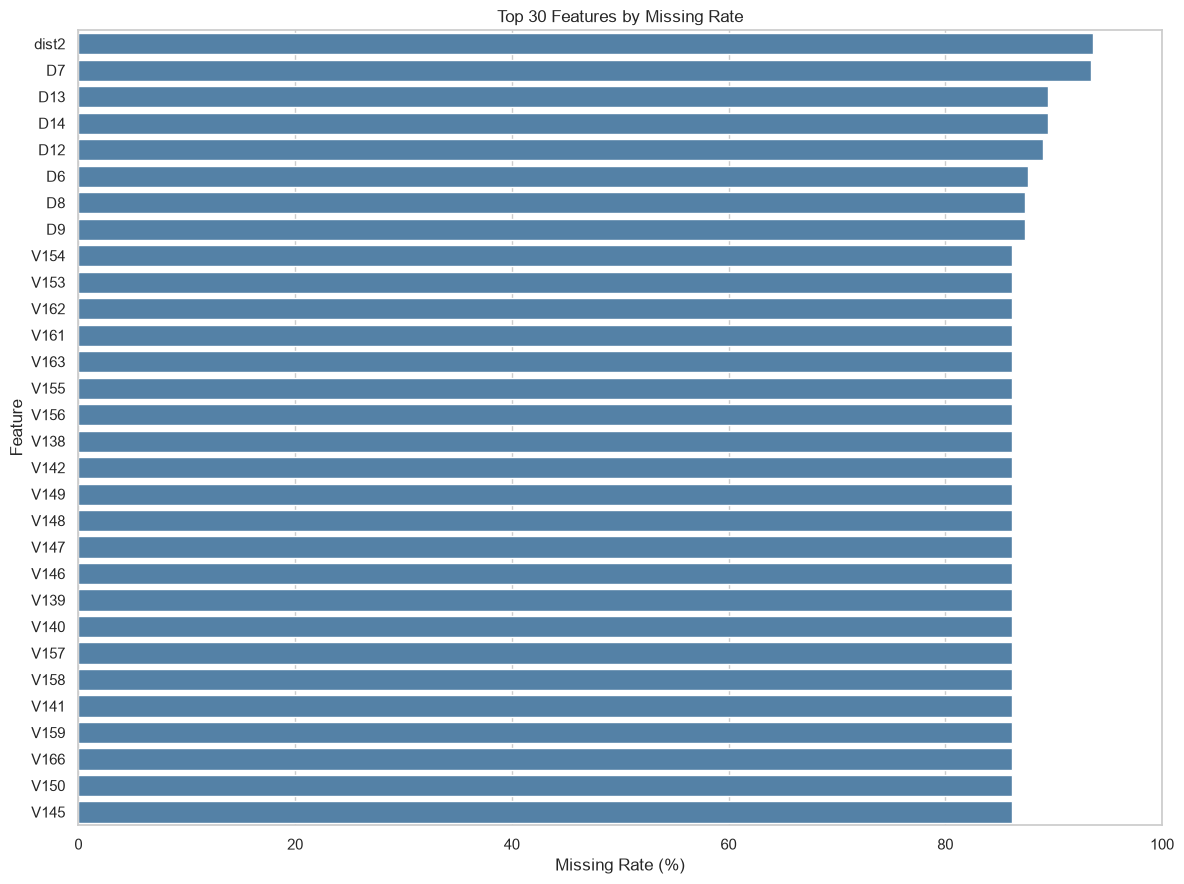

In [13]:
top_missing = missing_report.head(30)

plt.figure(figsize=(12, 9))

sns.barplot(data=top_missing, x="missing_rate_pct", y="column_name", color="steelblue")

plt.title("Top 30 Features by Missing Rate")
plt.xlabel("Missing Rate (%)")
plt.ylabel("Feature")

plt.xlim(0, 100)

plt.tight_layout()

plt.savefig(FIGURE_DIR / "transaction_top30_missing.png", dpi=300, bbox_inches="tight")

plt.show()

## 9. Kiểm tra Duplicate IDs

In [14]:
duplicates = duplicate_report(df, id_column=ID_COLUMN, check_full_rows=False)

display(duplicates)

export_report(duplicates, REPORT_DIR / "transaction_duplicates.csv")

,total_rows,duplicate_rows,duplicate_id_count,missing_id_count
0,590540,None,0,0


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_duplicates.csv


## 10. Kiểm tra tính hợp lệ của nhãn

In [15]:
target_report = target_validation(df, TARGET_COLUMN)

display(target_report.T)

export_report(target_report, REPORT_DIR / "transaction_target_validation.csv")

assert target_report.loc[0, "missing_labels"] == 0

assert target_report.loc[0, "invalid_labels"] == 0

,0
target_column,isFraud
total_rows,590540
missing_labels,0
invalid_labels,0
fraud_count,20663
legitimate_count,569877
fraud_rate_pct,3.499001


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_target_validation.csv


## 11. Class Distribution

In [16]:
class_distribution = target_distribution(df, TARGET_COLUMN)

display(class_distribution)

export_report(class_distribution, REPORT_DIR / "transaction_class_distribution.csv")

,label,count,percentage
0,0,569877,96.500999
1,1,20663,3.499001


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_class_distribution.csv


27,58 : 1
Khoảng 28 giao dịch hợp pháp trên mỗi giao dịch gian lận.

## 12. Vẽ biểu đồ phân phối nhãn

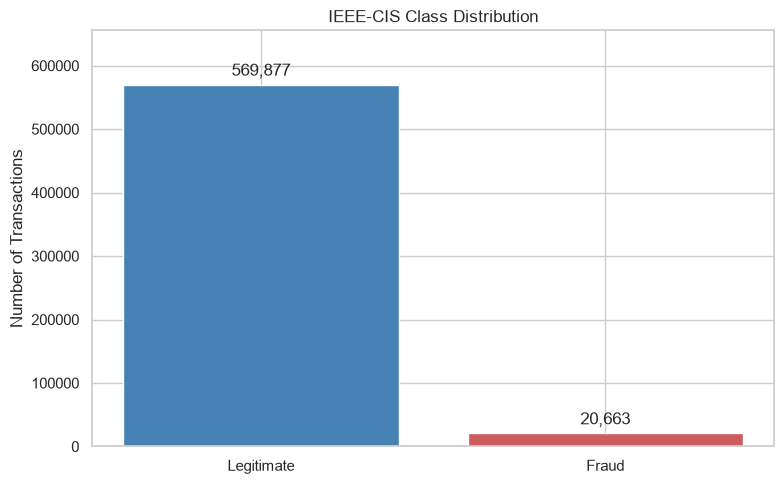

In [17]:
plot_data = class_distribution.copy()

plot_data["class_name"] = plot_data["label"].map({0: "Legitimate", 1: "Fraud"})

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_data["class_name"], plot_data["count"], color=["steelblue", "indianred"]
)

ax.bar_label(bars, labels=[f"{count:,}" for count in plot_data["count"]], padding=4)

ax.set_title("IEEE-CIS Class Distribution")
ax.set_ylabel("Number of Transactions")

ax.set_ylim(0, plot_data["count"].max() * 1.15)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "transaction_class_distribution.png", dpi=300, bbox_inches="tight"
)

plt.show()

## 12. Constant Features và All-missing Features

In [18]:
constant_features = profile.loc[profile["is_constant"]]

all_missing_features = profile.loc[profile["is_all_missing"]]

print("Constant features:", len(constant_features))

display(constant_features)

print("All-missing features:", len(all_missing_features))

display(all_missing_features)

export_report(constant_features, REPORT_DIR / "transaction_constant_features.csv")

export_report(all_missing_features, REPORT_DIR / "transaction_all_missing_features.csv")

Constant features: 0


,column_name,dtype,non_null_count,missing_count,missing_rate_pct,unique_count,unique_rate_pct,is_constant,is_all_missing


All-missing features: 0


,column_name,dtype,non_null_count,missing_count,missing_rate_pct,unique_count,unique_rate_pct,is_constant,is_all_missing


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_constant_features.csv
Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_all_missing_features.csv


## 13. Thống kê các thuộc tính số

In [19]:
numeric_stats = numerical_statistics(df)

display(numeric_stats.head(20))

export_report(numeric_stats, REPORT_DIR / "transaction_numeric_statistics.csv")

,column_name,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
0,TransactionID,590540.0,3.282270e+06,1.704744e+05,2987000.000,2992905.390,3134634.750,3282269.500,3429904.25,3548012.05,3571633.61,3.577539e+06
1,isFraud,590540.0,3.499001e-02,1.837546e-01,0.000,0.000,0.000,0.000,0.00,0.00,1.00,1.000000e+00
2,TransactionDT,590540.0,7.372311e+06,4.617224e+06,86400.000,185058.820,3027057.750,7306527.500,11246620.00,14857872.15,15629766.04,1.581113e+07
3,TransactionAmt,590540.0,1.350272e+02,2.391625e+02,0.251,9.244,43.321,68.769,125.00,445.00,1104.00,3.193739e+04
4,card1,590540.0,9.898735e+03,4.901170e+03,1000.000,1338.000,6019.000,9678.000,14184.00,17319.00,18238.00,1.839600e+04
5,card2,581607.0,3.625555e+02,1.577932e+02,100.000,100.000,214.000,361.000,512.00,567.00,583.00,6.000000e+02
6,card3,588975.0,1.531949e+02,1.133644e+01,100.000,144.000,150.000,150.000,150.00,185.00,185.00,2.310000e+02
7,card5,586281.0,1.992789e+02,4.124445e+01,100.000,102.000,166.000,226.000,226.00,226.00,226.00,2.370000e+02
8,addr1,524834.0,2.907338e+02,1.017411e+02,100.000,123.000,204.000,299.000,330.00,485.00,512.00,5.400000e+02
9,addr2,524834.0,8.680063e+01,2.690623e+00,10.000,87.000,87.000,87.000,87.00,87.00,87.00,1.020000e+02


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_numeric_statistics.csv


## Identity Data Inspection

The identity dataset contains additional device and
identity-related information.

Since the primary experimental configuration does not
include identity features, this section only verifies
data integrity, join keys, and transaction coverage.

## 14. Đọc dữ liệu Identity và đối chiếu Manifest

In [20]:
identity = load_ieee_identity()

print("Identity shape:", identity.shape)

display(identity.head())

identity_overview = dataset_overview(identity, dataset_name="IEEE-CIS Identity")

display(identity_overview.T)

export_report(identity_overview, REPORT_DIR / "identity_overview.csv")

Identity shape: (144233, 41)


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,...,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,NotFound,NaN,-480.0,...,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,NaN,100.0,NotFound,49.0,-300.0,...,NaN,NaN,New,NotFound,iOS 11.1.2,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,100.0,NotFound,52.0,NaN,...,NaN,NaN,Found,Found,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,NaN,100.0,NotFound,52.0,NaN,...,NaN,NaN,New,NotFound,NaN,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,0.0,100.0,NotFound,NaN,-300.0,...,NaN,NaN,Found,Found,Mac OS X 10_11_6,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


,0
dataset_name,IEEE-CIS Identity
num_rows,144233
num_columns,41
numeric_columns,24
non_numeric_columns,17
total_missing_values,2104107
missing_rate_pct,35.581097
memory_usage_mb,56.507504


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\identity_overview.csv


In [21]:
identity_record = manifest.loc[manifest["file_name"] == "train_identity.csv"]

assert len(identity_record) == 1, "Expected exactly one identity manifest record."

record = identity_record.iloc[0]

identity_integrity = pd.DataFrame(
    [
        {
            "property": "num_rows",
            "expected": int(record["num_rows"]),
            "actual": identity.shape[0],
        },
        {
            "property": "num_columns",
            "expected": int(record["num_columns"]),
            "actual": identity.shape[1],
        },
    ]
)

identity_integrity["is_match"] = (
    identity_integrity["expected"] == identity_integrity["actual"]
)

display(identity_integrity)

export_report(identity_integrity, REPORT_DIR / "identity_integrity.csv")

assert identity_integrity["is_match"].all()

,property,expected,actual,is_match
0,num_rows,144233,144233,True
1,num_columns,41,41,True


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\identity_integrity.csv


## 15. Kiểm tra khóa định danh

In [22]:
identity_duplicates = duplicate_report(
    identity, id_column=ID_COLUMN, check_full_rows=False
)

display(identity_duplicates)

export_report(identity_duplicates, REPORT_DIR / "identity_duplicates.csv")

assert identity_duplicates.loc[0, "duplicate_id_count"] == 0

assert identity_duplicates.loc[0, "missing_id_count"] == 0

,total_rows,duplicate_rows,duplicate_id_count,missing_id_count
0,144233,None,0,0


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\identity_duplicates.csv


## 16. Kiểm tra khả năng ghép dữ liệu

In [23]:
transaction_ids = df[ID_COLUMN]
identity_ids = identity[ID_COLUMN]

matched_transactions = transaction_ids.isin(identity_ids)

matched_identity = identity_ids.isin(transaction_ids)

join_report = pd.DataFrame(
    [
        {
            "total_transactions": len(df),
            "total_identity_records": len(identity),
            "transactions_with_identity": int(matched_transactions.sum()),
            "transactions_without_identity": int((~matched_transactions).sum()),
            "unmatched_identity_records": int((~matched_identity).sum()),
            "identity_coverage_pct": (matched_transactions.mean() * 100),
        }
    ]
)

display(join_report.T)

export_report(join_report, REPORT_DIR / "identity_join_coverage.csv")

assert join_report.loc[0, "unmatched_identity_records"] == 0

,0
total_transactions,590540.000000
total_identity_records,144233.000000
transactions_with_identity,144233.000000
transactions_without_identity,446307.000000
unmatched_identity_records,0.000000
identity_coverage_pct,24.423917


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\identity_join_coverage.csv


## 17. Giải phóng bộ nhớ

In [24]:
import gc

del identity
del transaction_ids
del identity_ids
del matched_transactions
del matched_identity

gc.collect()

8539

## Data Dictionary and Feature Groups

Features are grouped according to their documented
prefixes and general roles.

Anonymized features are not assigned unsupported
business meanings.

Feature eligibility is recorded for the planned
FullFeatures and NoCardID configurations.

## 18. Xây dựng Data Dictionary

In [25]:
import re


def describe_feature(column):

    descriptions = {
        "TransactionID": ("Identifier", "Unique transaction identifier"),
        "TransactionDT": ("Temporal", "Relative transaction time in seconds"),
        "isFraud": ("Target", "Binary fraud label"),
        "TransactionAmt": ("Amount", "Transaction amount"),
        "ProductCD": ("Product", "Product code"),
        "P_emaildomain": ("Email", "Purchaser email domain"),
        "R_emaildomain": ("Email", "Recipient email domain"),
    }

    if column in descriptions:
        return descriptions[column]

    patterns = [
        (r"card\d+", "Card", "Card-related feature"),
        (r"addr\d+", "Address", "Address-related feature"),
        (r"dist\d+", "Distance", "Distance-related feature"),
        (r"C\d+", "Count", "Anonymized counting feature"),
        (r"D\d+", "Time Delta", "Anonymized time delta feature"),
        (r"M\d+", "Match", "Anonymized matching feature"),
        (r"V\d+", "Vesta", "Anonymized Vesta feature"),
    ]

    for pattern, group, description in patterns:

        if re.fullmatch(pattern, column):
            return group, description

    return "Other", "Undocumented feature"


excluded = set(ieee_config["excluded_features"])

no_card_columns = set(ieee_config["no_card_id_columns"])

dictionary = []

for column in df.columns:

    group, description = describe_feature(column)

    dictionary.append(
        {
            "column_name": column,
            "feature_group": group,
            "description": description,
            "role": (
                "target"
                if column == TARGET_COLUMN
                else "metadata" if column in excluded else "candidate_feature"
            ),
            "full_features": column not in excluded,
            "no_card_id": (column not in excluded and column not in no_card_columns),
        }
    )

data_dictionary = pd.DataFrame(dictionary)

data_dictionary = data_dictionary.merge(
    profile[["column_name", "dtype", "missing_rate_pct", "unique_count"]],
    on="column_name",
    how="left",
    validate="one_to_one",
)

display(data_dictionary.head(20))

export_report(data_dictionary, REPORT_DIR / "transaction_data_dictionary.csv")

,column_name,feature_group,description,role,full_features,no_card_id,dtype,missing_rate_pct,unique_count
0,TransactionID,Identifier,Unique transaction identifier,metadata,False,False,int64,0.000000,590540
1,isFraud,Target,Binary fraud label,target,False,False,int64,0.000000,2
2,TransactionDT,Temporal,Relative transaction time in seconds,metadata,False,False,int64,0.000000,573349
3,TransactionAmt,Amount,Transaction amount,candidate_feature,True,True,float64,0.000000,20902
4,ProductCD,Product,Product code,candidate_feature,True,True,str,0.000000,5
5,card1,Card,Card-related feature,candidate_feature,True,False,int64,0.000000,13553
6,card2,Card,Card-related feature,candidate_feature,True,False,float64,1.512683,500
7,card3,Card,Card-related feature,candidate_feature,True,False,float64,0.265012,114
8,card4,Card,Card-related feature,candidate_feature,True,False,str,0.267044,4
9,card5,Card,Card-related feature,candidate_feature,True,False,float64,0.721204,119


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\transaction_data_dictionary.csv


## 19. Kiểm tra số lượng đặc trưng

In [26]:
feature_set_summary = pd.DataFrame(
    [
        {
            "feature_set": "FullFeatures",
            "num_features": int(data_dictionary["full_features"].sum()),
        },
        {
            "feature_set": "NoCardID",
            "num_features": int(data_dictionary["no_card_id"].sum()),
        },
    ]
)

display(feature_set_summary)

export_report(feature_set_summary, REPORT_DIR / "feature_set_summary.csv")

assert len(data_dictionary) == len(df.columns)

assert no_card_columns.issubset(df.columns)

,feature_set,num_features
0,FullFeatures,391
1,NoCardID,381


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\feature_set_summary.csv


## 20. Thống kê nhóm thuộc tính

In [27]:
feature_group_summary = (
    data_dictionary.groupby("feature_group")
    .agg(
        num_columns=("column_name", "count"),
        mean_missing_rate_pct=("missing_rate_pct", "mean"),
        full_features=("full_features", "sum"),
        no_card_id=("no_card_id", "sum"),
    )
    .reset_index()
    .sort_values("num_columns", ascending=False)
)

display(feature_group_summary)

export_report(feature_group_summary, REPORT_DIR / "feature_group_summary.csv")

,feature_group,num_columns,mean_missing_rate_pct,full_features,no_card_id
12,Vesta,339,43.038469,339,339
11,Time Delta,15,58.151263,15,15
3,Count,14,0.000000,14,14
7,Match,9,49.923328,9,9
2,Card,6,0.505328,6,0
0,Address,2,11.126427,2,0
4,Distance,2,76.640363,2,2
5,Email,2,46.373235,2,0
1,Amount,1,0.000000,1,1
8,Product,1,0.000000,1,1


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\ieee_cis\feature_group_summary.csv
